In [ ]:
import numpy as np
from scipy.integrate import trapezoid
import matplotlib.pyplot as plt
from scipy.optimize import fsolve
from scipy.optimize import brentq
from scipy.stats import skew, kurtosis
from scipy.signal import welch

In [ ]:
#parameters
Hs = 6.0       # Significant wave height [m]
g = 9.81       # Gravitational acceleration [m/s^2]
s0p = 0.05     # Chosen deep-water wave steepness Hs / lambda_0p [-] (typical steep wind sea: 0.035 - 0.040)

# Calculate peak period Tp [s]
Tp = np.sqrt((2 * np.pi * Hs) / (g * s0p))

# Equivalent dimensionless steepness ka = pi * s0p (Lecture 3, Slide 3 & 9)
ka = np.pi * s0p

print(f"Peak period Tp = {Tp:.2f} s")
print(f"Steepness ka   = {ka:.3f}")

In [ ]:
fp = 1.0 / Tp   # Peak frequency [Hz]

# JONSWAP parameters (Lecture 5, slide 12)
gamma = 3.3
sigma_a = 0.07  # for f <= fp
sigma_b = 0.09  # for f > fp

# 2. Frequency grid (avoid f = 0 to prevent division by zero)
f = np.linspace(0.01, 1.0, 10000)
sigma = np.where(f <= fp, sigma_a, sigma_b)

# 3. Pierson-Moskowitz spectrum E_PM(f)
E_PM = (5.0 / 16.0) * (Hs**2) * (fp**4) * (f**(-5)) * np.exp(-1.25 * (fp / f)**4)

# 4. JONSWAP spectrum E(f) with normalizing factor A_gamma
A_gamma = 1.0 - 0.287 * np.log(gamma)
peak_enhancement = gamma ** np.exp(-((f - fp)**2) / (2.0 * (sigma**2) * (fp**2)))
E = A_gamma * E_PM * peak_enhancement

# 5. Compute spectral moments
m_minus1 = trapezoid(f**(-1) * E, f)
m0 = trapezoid(E, f)
m1 = trapezoid(f**1 * E, f)
m2 = trapezoid(f**2 * E, f)

# 6. Compute characteristic wave periods
Tm_10 = m_minus1 / m0        # Energy period T_{m-1,0}
Tm01 = m0 / m1               # Mean spectral period T_{m01}
Tm02 = np.sqrt(m0 / m2)      # Mean zero-crossing period T_{m02} (T_z / T_m)

print(f"A_gamma         = {A_gamma:.5f}")
print(f"m0              = {m0:.4f} m^2  (target Hs^2/16 = {Hs**2 / 16:.4f} m^2)")
print(f"Check Hs (4√m0) = {4 * np.sqrt(m0):.3f} m")
print(f"T_m-1,0         = {Tm_10:.2f} s")
print(f"T_m01           = {Tm01:.2f} s")
print(f"T_m02 (T_m)     = {Tm02:.2f} s")

# 7. Plot both PM and JONSWAP spectra for comparison
plt.figure(figsize=(8, 4.5))
plt.plot(f, E_PM, color="#1b263b", linestyle="--", linewidth=1.8, label="PM (γ = 1.0)")
plt.plot(f, E, color="#00a6d6", linewidth=2.2, label=f"JONSWAP (γ = {gamma})")
plt.fill_between(f, E, alpha=0.15, color="#00a6d6")
plt.axvline(fp, color="#d62728", linestyle=":", linewidth=1.2, label=f"fp = {fp:.3f} Hz")

plt.xlim(0, 0.35)
plt.ylim(0, np.max(E) * 1.1)
plt.xlabel("Frequency f [Hz]")
plt.ylabel("Variance Density E(f) [m²/Hz]")
plt.title(f"JONSWAP vs. PM Spectrum (Hs = {Hs} m, Tp = {Tp} s)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Peak frequency fp = {fp:.3f} Hz")

In [ ]:
h = 20.0  # Water depth [m]

def local_wave_steepness(Hs, T, h):
    omega = 2 * np.pi / T
    # Solve omega^2 = g * k * tanh(k * h) using deep-water k0 as initial guess
    k = fsolve(lambda k: omega**2 - g * k * np.tanh(k * h), omega**2 / g)[0]
    L = 2 * np.pi / k
    return Hs / L, L, k

for name, T in [("Tp", Tp), ("T_m-1,0", Tm_10), ("T_m01", Tm01), ("T_m02", Tm02)]:
    s, L, k = local_wave_steepness(Hs, T, h)
    print(f"{name:7s} = {T:.2f} s  ->  L = {L:6.2f} m,  s = {s:.4f}")

In [ ]:
# 1. Wave and site parameters
Hs = 6.0        # Significant wave height [m]
Tp = 8.77      # Peak period [s]
fp = 1.0 / Tp   # Peak frequency [Hz]
gamma = 3.3     # JONSWAP peak enhancement factor
h = 20.0        # Water depth [m]
g = 9.81        # Gravity [m/s^2]
z = 0.0         # Evaluation elevation [m] (mean water level)

# 2. Time and frequency grids
D = 10800.0      # Record duration [s] (180 minutes)
dt = 0.25       # Time step [s]
t = np.arange(0, D, dt)

df = 1.0 / D    # Frequency resolution [Hz] (prevents repetition within D)
f = np.arange(0.02, 0.5, df)  # Frequency array [Hz] (avoid f = 0)
omega = 2 * np.pi * f

# 3. JONSWAP variance density spectrum E(f) (Lecture 5)
sigma = np.where(f <= fp, 0.07, 0.09)
A_gamma = 1.0 - 0.287 * np.log(gamma)
E_PM = (5.0 / 16.0) * (Hs**2) * (fp**4) * (f**(-5)) * np.exp(-1.25 * (fp / f)**4)
E = A_gamma * E_PM * (gamma ** np.exp(-((f - fp)**2) / (2.0 * (sigma**2) * (fp**2))))

# 4. Solve linear dispersion relation k(f) for every frequency component
k = np.array([
    fsolve(lambda ki: w**2 - g * ki * np.tanh(ki * h), w**2 / g)[0]
    for w in omega
])

# 5. Linear transfer function for horizontal velocity u at elevation z
H_u = omega * np.cosh(k * (z + h)) / np.sinh(k * h)

# 6. Random-phase synthesis
rng = np.random.default_rng(42)            # Fixed seed for reproducibility
a = np.sqrt(2.0 * E * df)                  # Component amplitudes [m]
alpha = rng.uniform(0, 2 * np.pi, len(f))  # Random phases in [0, 2*pi)

# Vectorized summation over all frequency components
phase = omega[:, None] * t[None, :] + alpha[:, None]
eta = np.sum(a[:, None] * np.cos(phase), axis=0)
u = np.sum((H_u * a)[:, None] * np.cos(phase), axis=0)

# 7. Sanity checks
print(f"eta(t):   std = {np.std(eta):.3f} m  |  4*std (Hs check) = {4*np.std(eta):.3f} m  |  max = {np.max(eta):.2f} m")
print(f"u(0, t):  u_rms = {np.std(u):.3f} m/s  |  max = {np.max(u):.2f} m/s")

# 8. Plot first 120 seconds of both time series
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax1.plot(t, eta, color="#00a6d6", linewidth=1.2)
ax1.axhline(0, color="gray", linewidth=0.8, linestyle="--")
ax1.set_ylabel(r"$\eta(t)$ [m]")
ax1.set_title(f"Linear Random-Phase Wave Field at z = {z} m (Hs = {Hs} m, Tp = {Tp} s, h = {h} m)")
ax1.grid(True, linestyle=":", alpha=0.6)

ax2.plot(t, u, color="#e6550d", linewidth=1.2)
ax2.axhline(0, color="gray", linewidth=0.8, linestyle="--")
ax2.set_xlabel("Time t [s]")
ax2.set_ylabel(r"$u(z=0, t)$ [m/s]")
ax2.set_xlim(0, 120)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

Sea state: Hs = 6.00 m, Tp = 8.77 s (s0p = 0.05), h = 20.0 m, N_f = 3564
Linear eta1 : 4*std = 6.000 m | max = +6.25 m | min = -6.22 m | skew = +0.015 | kurt = 3.06
2nd-ord eta2:   std = 0.311 m | max = +2.41 m | min = -2.72 m
Total  eta  : 4*std = 6.133 m | max = +8.66 m | min = -4.47 m | skew = +0.588 | kurt = 3.59
Linear u1(0):   std = 1.446 m/s | max = +6.02 m/s | min = -5.57 m/s
Total  u(0) :   std = 1.454 m/s | max = +6.78 m/s | min = -4.59 m/s


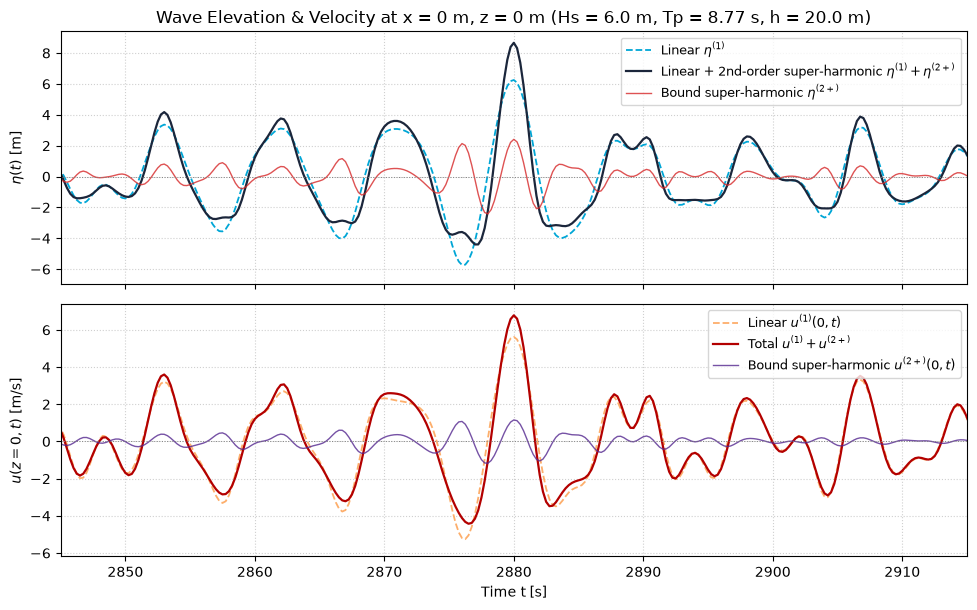

In [38]:
# ============================================================
# 1. Shared Site & Sea-State Parameters (consistent with Q3)
# ============================================================
Hs = 6.0        # Significant wave height [m] (Table 2, col 1)
h = 20.0        # Water depth [m] (Table 2, col 1)
g = 9.81        # Gravitational acceleration [m/s^2]
s0p = 0.05     # Deep-water peak steepness [-] (matches JONSWAP gamma = 3.3)
Tp = np.sqrt((2.0 * np.pi * Hs) / (g * s0p))  # Peak period [s] (~9.80 s)
gamma = 3.3     # JONSWAP peak enhancement factor

# Discretization parameters
D = 10800.0      # Record duration [s] (1 hour)
dt = 0.25       # Time step [s] (f_Nyq = 2.0 Hz > 2 * f_max)
f_min = 0.02    # Lower cutoff frequency [Hz] (~0.2 * fp)
f_max = 0.35    # Upper cutoff frequency [Hz] (~3.4 * fp, avoids 2nd-order tail blowup)


# ============================================================
# 2. Helper Functions (reusable for Parts I, II, and III)
# ============================================================
def solve_dispersion(omega, h, g=9.81):
    """Solve linear dispersion relation omega^2 = g*k*tanh(k*h) robustly."""
    k = np.empty_like(omega, dtype=float)
    for idx, w in enumerate(omega):
        k_low = 0.5 * w / np.sqrt(g * h)
        k_high = max(2.0 * w**2 / g, 2.0 * w / np.sqrt(g * h)) + 1.0
        k[idx] = brentq(lambda ki: w**2 - g * ki * np.tanh(ki * h), k_low, k_high)
    return k


def jonswap_spectrum(f, Hs, Tp, gamma=3.3, normalize=True):
    """Compute JONSWAP variance density spectrum E(f) [m^2/Hz]."""
    fp = 1.0 / Tp
    sigma = np.where(f <= fp, 0.07, 0.09)
    A_gamma = 1.0 - 0.287 * np.log(gamma)
    E_PM = (5.0 / 16.0) * (Hs**2) * (fp**4) * (f**(-5)) * np.exp(-1.25 * (fp / f)**4)
    E = A_gamma * E_PM * (gamma ** np.exp(-((f - fp)**2) / (2.0 * (sigma**2) * (fp**2))))
    if normalize:
        # Exact variance normalization so 4*sqrt(m0) == Hs despite finite [f_min, f_max]
        df_loc = f[1] - f[0]
        E *= (Hs**2 / 16.0) / np.sum(E * df_loc)
    return E


def build_linear_components(Hs, Tp, h, D=10800.0, dt=0.25, f_min=0.02, f_max=0.35,
                            gamma=3.3, g=9.81, seed=41):
    """Build discrete frequency grid, amplitudes, wavenumbers, and random phases."""
    N_t = int(round(D / dt))
    df = 1.0 / D

    # Integer harmonic indices prevent floating-point drift & enable exact FFT synthesis
    n_min = int(np.ceil(f_min / df))
    n_max = int(np.floor(f_max / df))
    assert 2 * n_max < N_t // 2, "Increase sampling rate (decrease dt) to avoid 2nd-order aliasing!"

    n_idx = np.arange(n_min, n_max + 1)
    f = n_idx * df
    omega = 2.0 * np.pi * f
    k = solve_dispersion(omega, h, g)
    E = jonswap_spectrum(f, Hs, Tp, gamma=gamma, normalize=True)

    a = np.sqrt(2.0 * E * df)
    rng = np.random.default_rng(seed)
    alpha = rng.uniform(0.0, 2.0 * np.pi, len(f))

    return {
        "N_t": N_t, "dt": dt, "D": D, "t": np.arange(N_t) * dt,
        "df": df, "n_idx": n_idx, "f": f, "omega": omega,
        "k": k, "E": E, "a": a, "alpha": alpha, "h": h, "g": g
    }


def synthesize_wave_field(comp, z=0.0, x=0.0, include_second_order=True):
    """
    Evaluate linear (Q4a) and 2nd-order super-harmonic (Q4b) wave elevation eta(t)
    and horizontal velocity u(z, t) at location (x, z) via exact FFT synthesis.
    Phase convention: cos(omega*t - k*x + alpha).
    """
    N_t = comp["N_t"]
    n_idx, omega, k = comp["n_idx"], comp["omega"], comp["k"]
    a, alpha = comp["a"], comp["alpha"]
    h, g = comp["h"], comp["g"]

    # Complex amplitudes at location x: Re[C1 * exp(+i*omega*t)] = a * cos(omega*t - k*x + alpha)
    C1 = a * np.exp(1j * (alpha - k * x))

    # --- Q4a: Linear wave field ---
    # Overflow-safe exponential form of cosh(k*(z+h)) / sinh(k*h) for z <= 0
    H_u = omega * (np.exp(k * z) + np.exp(-k * (z + 2.0 * h))) / (1.0 - np.exp(-2.0 * k * h))

    X_eta1 = np.zeros(N_t // 2 + 1, dtype=np.complex128)
    X_u1 = np.zeros(N_t // 2 + 1, dtype=np.complex128)
    X_eta1[n_idx] = (N_t / 2.0) * C1
    X_u1[n_idx] = (N_t / 2.0) * H_u * C1

    eta1 = np.fft.irfft(X_eta1, n=N_t)
    u1 = np.fft.irfft(X_u1, n=N_t)

    result = {"t": comp["t"], "eta1": eta1, "u1": u1}

    if not include_second_order:
        return result

    # --- Q4b: Second-order super-harmonic bound waves (Sharma & Dean, 1981) ---
    X_eta2 = np.zeros(N_t // 2 + 1, dtype=np.complex128)
    X_u2 = np.zeros(N_t // 2 + 1, dtype=np.complex128)

    term_self = (g**2 * k**2 - omega**4) / omega
    N_f = len(omega)

    # Loop over i and vectorize over j >= i using pair symmetry (weight 1 for j==i, 2 for j>i)
    for i in range(N_f):
        wi, ki, Ci, ni = omega[i], k[i], C1[i], n_idx[i]
        wj, kj, Cj, nj = omega[i:], k[i:], C1[i:], n_idx[i:]

        w_p = wi + wj
        k_p = ki + kj

        S_plus = 0.5 * w_p * ((g**2 * ki * kj) / (wi * wj) - wi * wj) + 0.25 * (term_self[i] + term_self[i:])
        D_plus = g * k_p * np.tanh(k_p * h) - w_p**2
        B_plus = S_plus / D_plus

        G_eta = (-w_p * B_plus + 0.25 * (wi**2 + wi * wj + wj**2 - (g**2 * ki * kj) / (wi * wj))) / g

        # Overflow-safe exponential form of cosh(k_p*(z+h)) / cosh(k_p*h) for z <= 0
        vert_u2 = (np.exp(k_p * z) + np.exp(-k_p * (z + 2.0 * h))) / (1.0 + np.exp(-2.0 * k_p * h))
        G_u = -k_p * B_plus * vert_u2

        weights = np.full_like(wj, 2.0)
        weights[0] = 1.0  # Self-interaction (i == j) counted once

        C_prod = weights * Ci * Cj
        n_sum = ni + nj

        np.add.at(X_eta2, n_sum, (N_t / 2.0) * G_eta * C_prod)
        np.add.at(X_u2, n_sum, (N_t / 2.0) * G_u * C_prod)

    eta2 = np.fft.irfft(X_eta2, n=N_t)
    u2 = np.fft.irfft(X_u2, n=N_t)

    result.update({
        "eta2": eta2, "eta": eta1 + eta2,
        "u2": u2, "u": u1 + u2
    })
    return result


# ============================================================
# 3. Run Simulation at (x = 0, z = 0)
# ============================================================
comp = build_linear_components(Hs, Tp, h, D=D, dt=dt, f_min=f_min, f_max=f_max, gamma=gamma, seed=41)
wf = synthesize_wave_field(comp, z=0.0, x=0.0, include_second_order=True)

t = wf["t"]
eta1, eta2, eta = wf["eta1"], wf["eta2"], wf["eta"]
u1, u2, u = wf["u1"], wf["u2"], wf["u"]

print(f"Sea state: Hs = {Hs:.2f} m, Tp = {Tp:.2f} s (s0p = {s0p}), h = {h:.1f} m, N_f = {len(comp['f'])}")
print(f"Linear eta1 : 4*std = {4*np.std(eta1):.3f} m | max = {np.max(eta1):+.2f} m | min = {np.min(eta1):+.2f} m | skew = {skew(eta1):+.3f} | kurt = {kurtosis(eta1, fisher=False):.2f}")
print(f"2nd-ord eta2:   std = {np.std(eta2):.3f} m | max = {np.max(eta2):+.2f} m | min = {np.min(eta2):+.2f} m")
print(f"Total  eta  : 4*std = {4*np.std(eta):.3f} m | max = {np.max(eta):+.2f} m | min = {np.min(eta):+.2f} m | skew = {skew(eta):+.3f} | kurt = {kurtosis(eta, fisher=False):.2f}")
print(f"Linear u1(0):   std = {np.std(u1):.3f} m/s | max = {np.max(u1):+.2f} m/s | min = {np.min(u1):+.2f} m/s")
print(f"Total  u(0) :   std = {np.std(u):.3f} m/s | max = {np.max(u):+.2f} m/s | min = {np.min(u):+.2f} m/s")

# ============================================================
# 4. Plot Around the Largest Crest (makes 2nd-order sharpening clearly visible)
# ============================================================
t_peak = t[np.argmax(eta)]
t_win = (max(0, t_peak - 35), min(D, t_peak + 35))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True)

ax1.plot(t, eta1, color="#00a6d6", linewidth=1.3, linestyle="--", label=r"Linear $\eta^{(1)}$")
ax1.plot(t, eta, color="#1b263b", linewidth=1.6, label=r"Linear + 2nd-order super-harmonic $\eta^{(1)} + \eta^{(2+)}$")
ax1.plot(t, eta2, color="#d62728", linewidth=1.0, alpha=0.8, label=r"Bound super-harmonic $\eta^{(2+)}$")
ax1.axhline(0, color="gray", linewidth=0.7, linestyle=":")
ax1.set_ylabel(r"$\eta(t)$ [m]")
ax1.set_title(f"Wave Elevation & Velocity at x = 0 m, z = 0 m (Hs = {Hs} m, Tp = {Tp:.2f} s, h = {h} m)")
ax1.legend(loc="upper right", fontsize=9)
ax1.grid(True, linestyle=":", alpha=0.6)

ax2.plot(t, u1, color="#fdae6b", linewidth=1.3, linestyle="--", label=r"Linear $u^{(1)}(0, t)$")
ax2.plot(t, u, color="#b30000", linewidth=1.6, label=r"Total $u^{(1)} + u^{(2+)}$")
ax2.plot(t, u2, color="#54278f", linewidth=1.0, alpha=0.8, label=r"Bound super-harmonic $u^{(2+)}(0, t)$")
ax2.axhline(0, color="gray", linewidth=0.7, linestyle=":")
ax2.set_xlabel("Time t [s]")
ax2.set_ylabel(r"$u(z=0, t)$ [m/s]")
ax2.set_xlim(t_win)
ax2.legend(loc="upper right", fontsize=9)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
# --- Verification 1: Single monochromatic wave vs. Analytical Stokes 2nd-order ---
T0, a0, alpha0, x_test, z_test = 10.0, 1.5, 0.7, 12.3, -3.5
D_test, dt_test = 100.0, 0.25
N_test = int(round(D_test / dt_test))
df_test = 1.0 / D_test
n0 = int(round((1.0 / T0) / df_test))
w0 = 2.0 * np.pi * n0 * df_test
k0 = solve_dispersion(np.array([w0]), h, g)[0]

comp_mono = {
    "N_t": N_test, "dt": dt_test, "D": D_test, "t": np.arange(N_test) * dt_test,
    "df": df_test, "n_idx": np.array([n0]), "f": np.array([n0 * df_test]),
    "omega": np.array([w0]), "k": np.array([k0]), "a": np.array([a0]),
    "alpha": np.array([alpha0]), "h": h, "g": g
}
wf_mono = synthesize_wave_field(comp_mono, z=z_test, x=x_test, include_second_order=True)

psi0 = w0 * comp_mono["t"] - k0 * x_test + alpha0
eta2_stokes = (k0 * a0**2 / 4.0) * np.cosh(k0 * h) * (2.0 * np.cosh(k0 * h)**2 + 1.0) / (np.sinh(k0 * h)**3) * np.cos(2.0 * psi0)
u2_stokes = (3.0 / 4.0) * (a0**2) * w0 * k0 * (np.cosh(2.0 * k0 * (z_test + h)) / (np.sinh(k0 * h)**4)) * np.cos(2.0 * psi0)

print("Verification 1 — Monochromatic test vs. Analytical Stokes 2nd-order:")
print(f"  Max |eta2_model - eta2_stokes| = {np.max(np.abs(wf_mono['eta2'] - eta2_stokes)):.2e} m")
print(f"  Max |u2_model   - u2_stokes|   = {np.max(np.abs(wf_mono['u2'] - u2_stokes)):.2e} m/s")

# --- Verification 2: Spectral recovery (Welch PSD vs. Target JONSWAP & bound tail) ---
f_w, P_eta1 = welch(eta1, fs=1.0 / dt, nperseg=1024)
_, P_eta_tot = welch(eta, fs=1.0 / dt, nperseg=1024)

plt.figure(figsize=(8.5, 4.2))
plt.semilogy(comp["f"], comp["E"], color="#1b263b", linewidth=2.0, label="Target JONSWAP E(f)")
plt.semilogy(f_w, P_eta1, color="#00a6d6", linestyle="--", linewidth=1.4, label=r"Simulated linear $\eta^{(1)}$ (Welch PSD)")
plt.semilogy(f_w, P_eta_tot, color="#d62728", linewidth=1.4, label=r"Simulated $\eta^{(1)} + \eta^{(2+)}$ (Welch PSD)")
plt.xlim(0, 0.7)
plt.ylim(1e-5, 2 * np.max(comp["E"]))
plt.xlabel("Frequency f [Hz]")
plt.ylabel(r"Variance Density $E(f)$ [$\mathrm{m}^2/\mathrm{Hz}$]")
plt.title("Model Verification: Spectral Recovery and 2nd-Order Super-Harmonic Energy around 2fp")
plt.grid(True, which="both", linestyle=":", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## Question 6 + 7 ##

In [ ]:
# Q6a - Near-bed kinematics
rho = 1025
z_bed = -h
H_bed = omega / np.sinh(k*h)
u_bed = np.sum((H_bed*a)[:, None]*np.cos(phase), axis=0)
H_dpdx = rho*omega**2 / np.sinh(k*h)
dpdx_bed = np.sum((H_dpdx*a)[:, None]*np.sin(phase), axis=0)

# Q6b - Reuse the Q4 linear surface velocity
u_surface = u

for name, signal, unit in [
    ("Near-bed velocity", u_bed, "m/s"),
    ("Near-surface velocity", u_surface, "m/s"),
    ("Near-bed pressure gradient", dpdx_bed, "Pa/m")
]:
    print(name)
    print(f"Mean = {np.mean(signal):.3f} {unit}")
    print(f"Std = {np.std(signal):.3f} {unit}")
    print(f"Maximum = {np.max(signal):.3f} {unit}")
    print(f"Minimum = {np.min(signal):.3f} {unit}")
    print(f"Absolute maximum = {np.max(np.abs(signal)):.3f} {unit}")

In [ ]:
# Time series
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(t, u_surface, color="#e6550d", label="Near-surface velocity")
ax1.plot(t, u_bed, color="#00a6d6", label="Near-bed velocity")
ax1.axhline(0, color="gray", linestyle="--")
ax1.set_ylabel("Velocity [m/s]")
ax1.set_title("Wave-induced horizontal velocities")
ax1.legend()
ax1.grid(True, linestyle=":", alpha=0.6)
ax2.plot(t, dpdx_bed, color="#1b263b")
ax2.axhline(0, color="gray", linestyle="--")
ax2.set_ylabel("Pressure gradient [Pa/m]")
ax2.set_xlabel("Time [s]")
ax2.set_title("Near-bed pressure gradient")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.set_xlim(0, 120)
plt.tight_layout()
plt.show()

In [ ]:
# Q6 - Spectral verification
H_surface = H_u
E_bed = H_bed**2 * E
E_surface = H_surface**2 * E
E_dpdx = H_dpdx**2 * E
for name, signal, spectrum, unit in [
    ("Near-bed velocity", u_bed, E_bed, "m/s"),
    ("Near-surface velocity", u_surface, E_surface, "m/s"),
    ("Pressure gradient", dpdx_bed, E_dpdx, "Pa/m")
]:
    sigma_time = np.std(signal)
    sigma_spectrum = np.sqrt(np.sum(spectrum*df))
    print(f"{name}: time = {sigma_time:.3f}, spectrum = {sigma_spectrum:.3f} {unit}")

plt.figure(figsize=(8, 4.5))
plt.plot(f, E/np.sum(E*df), label="Surface elevation")
plt.plot(f, E_bed/np.sum(E_bed*df), label="Near-bed velocity")
plt.plot(f, E_surface/np.sum(E_surface*df), label="Near-surface velocity")
plt.plot(f, E_dpdx/np.sum(E_dpdx*df), label="Near-bed pressure gradient")
plt.xlabel("Frequency [Hz]")
plt.ylabel("Normalised variance density [1/Hz]")
plt.title("Comparison of normalised spectra")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
# Optional Q6: empirical exceedance of positive cycle maxima
def cycle_maxima(signal):
    crossings = np.where((signal[:-1] <= 0) & (signal[1:] > 0))[0] + 1
    return np.array([np.max(signal[i:j]) for i, j in zip(crossings[:-1], crossings[1:])])

plt.figure(figsize=(8, 4.5))
for name, signal in [("Near-bed velocity", u_bed), ("Near-surface velocity", u_surface), ("Pressure gradient", dpdx_bed)]:
    peaks = np.sort(cycle_maxima(signal))[::-1] / np.std(signal)
    P = np.arange(1, len(peaks)+1)/(len(peaks)+1)
    plt.semilogy(peaks, P, ".", label=name)
x = np.linspace(0, 5, 200)
plt.semilogy(x, np.exp(-x**2/2), "k--", label="Rayleigh")
plt.xlabel("Positive cycle maximum / standard deviation [-]")
plt.ylabel("Exceedance probability [-]")
plt.ylim(1e-3, 1)
plt.legend()
plt.grid(True, which="both", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
# Q7 - Characteristic dimensionless numbers (same Tp as Q4)
W = 60.0  # Wall width [m]
omega_p = 2*np.pi/Tp
k_p = fsolve(lambda kp: omega_p**2 - g*kp*np.tanh(kp*h), omega_p**2/g)[0]
lambda_p = 2*np.pi/k_p
print(f"Peak period = {Tp:.2f} s")
print(f"Local wavelength = {lambda_p:.2f} m")
print(f"k_p h = {k_p*h:.3f}")
print(f"k_p a = {k_p*Hs/2:.3f}")
print(f"Hs/lambda_p = {Hs/lambda_p:.3f}")
print(f"Ursell number = {Hs*lambda_p**2/h**3:.3f}")
print(f"W/lambda_p = {W/lambda_p:.3f}")
print(f"Hs/h = {Hs/h:.3f}")